In [1]:
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

In [2]:
f_s = 50
f_e = 500
Voltage = 1.0
Dir_path = str(f_s) + "-" + str(f_e) + "Hz_" + str(Voltage) + "V"
Coeffs = []

with open('Coeff.txt') as file:
  for line in file:
    Coeffs.append(10000/float(line.strip()))
m = np.mean(Coeffs)
Coeffs = Coeffs/m

In [3]:
with open('..\static\save_data\collected_data_1743504995.json', 'r', encoding='utf-8') as f:
    data = json.load(f)

In [4]:
import numpy as np

SAMPLE_RATE = 10000
MIN_FREQ = 50
MAX_FREQ = 500
TOTAL_DURATION_SEC =10

def map_frequency(value, min_value, max_value):
    log_min = np.log10(MIN_FREQ)  # log10(50)
    log_max = np.log10(MAX_FREQ)  # log10(500)
    log_freq = log_min + (log_max - log_min) * ((value - min_value) / (max_value - min_value))
    return 10 ** log_freq


def linterp_index(arr, perc):
    index = perc * (len(arr) - 1)
    lower = int(np.floor(index))
    upper = int(np.ceil(index))
    weight = index - lower
    value = arr[lower] * (1 - weight) + arr[upper] * weight
    return value

def generate_signal(vib_amp, vib_freq, duration=None):
    if duration is None:
        duration = TOTAL_DURATION_SEC

    active_perc = duration / TOTAL_DURATION_SEC
    num_output_samples = int(duration * SAMPLE_RATE)
    vib_signal = np.zeros(num_output_samples, dtype=np.float32)

    phase_acc = 0
    for i in range(num_output_samples):
        perc = i / num_output_samples
        lperc = perc * active_perc

        s_freq = linterp_index(vib_freq, lperc)
        s_amp = linterp_index(vib_amp, lperc)

        current_freq = map_frequency(s_freq, 0, 1)
        phase_delta = 2 * np.pi * current_freq / SAMPLE_RATE

        phase_acc += phase_delta
        vib_signal[i] = s_amp * np.sin(phase_acc) * Coeffs[int(current_freq) - 50] ## 추가함함

    return vib_signal, duration


In [ ]:

vib_signal = data['vib_signal']  # 웹에서 생성된 waveform
vib_amp = data['vib_amp']        # draw canvas의 진폭 (0~1)
vib_freq = data['vib_freq']      # draw canvas의 주파수 (0~1)
thr_amp = data['thermal_signal'] # 이미 -6~6으로 정규화된 thermal signal

vib_signal_result,  duration = generate_signal(vib_amp, vib_freq, duration=10.0)

KeyError: 'vib_freq'

In [7]:

vib_signal = data['vib_signal']  # 웹에서 생성된 waveform
# vib_amp = data['vib_amp']        # draw canvas의 진폭 (0~1)
# vib_freq = data['vib_freq']      # draw canvas의 주파수 (0~1)
thr_amp = data['thermal_signal'] # 이미 -6~6으로 정규화된 thermal signal

# vib_signal_result,  duration = generate_signal(vib_amp, vib_freq, duration=10.0)

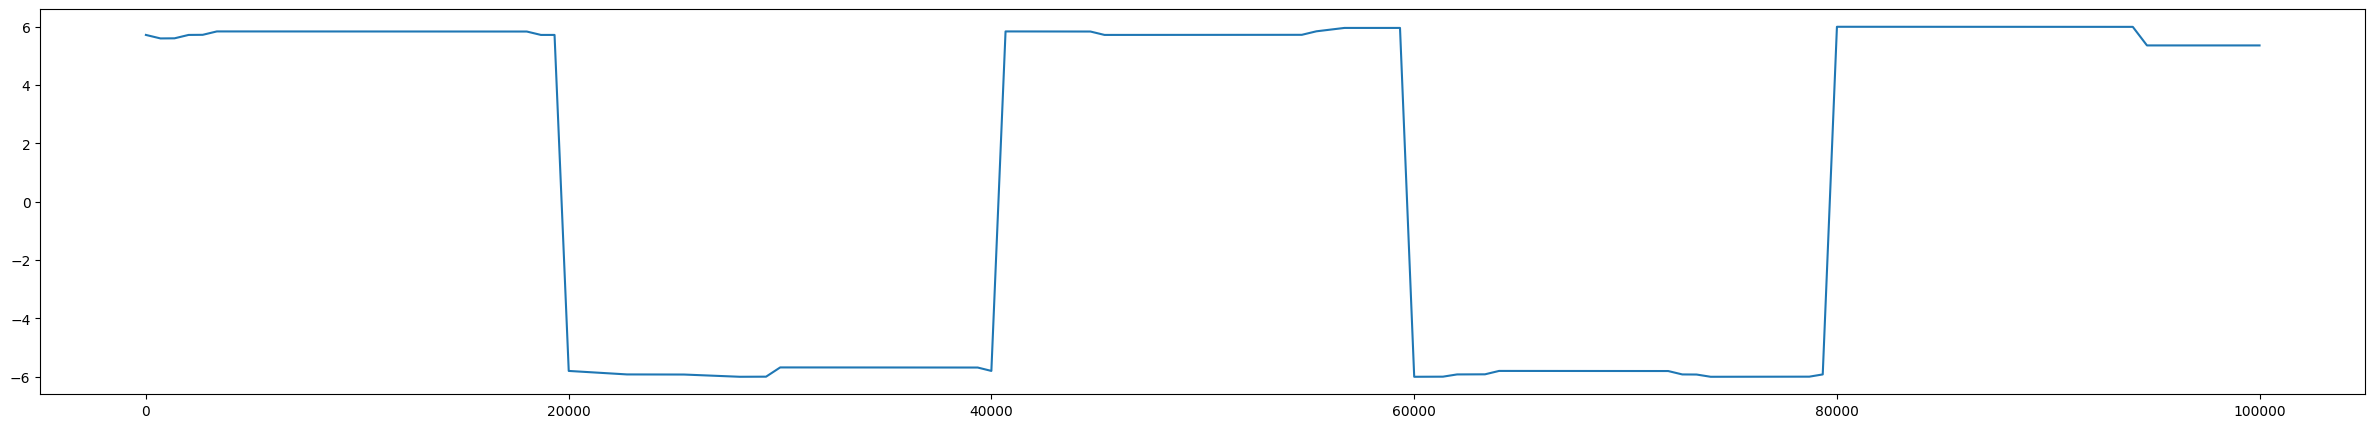

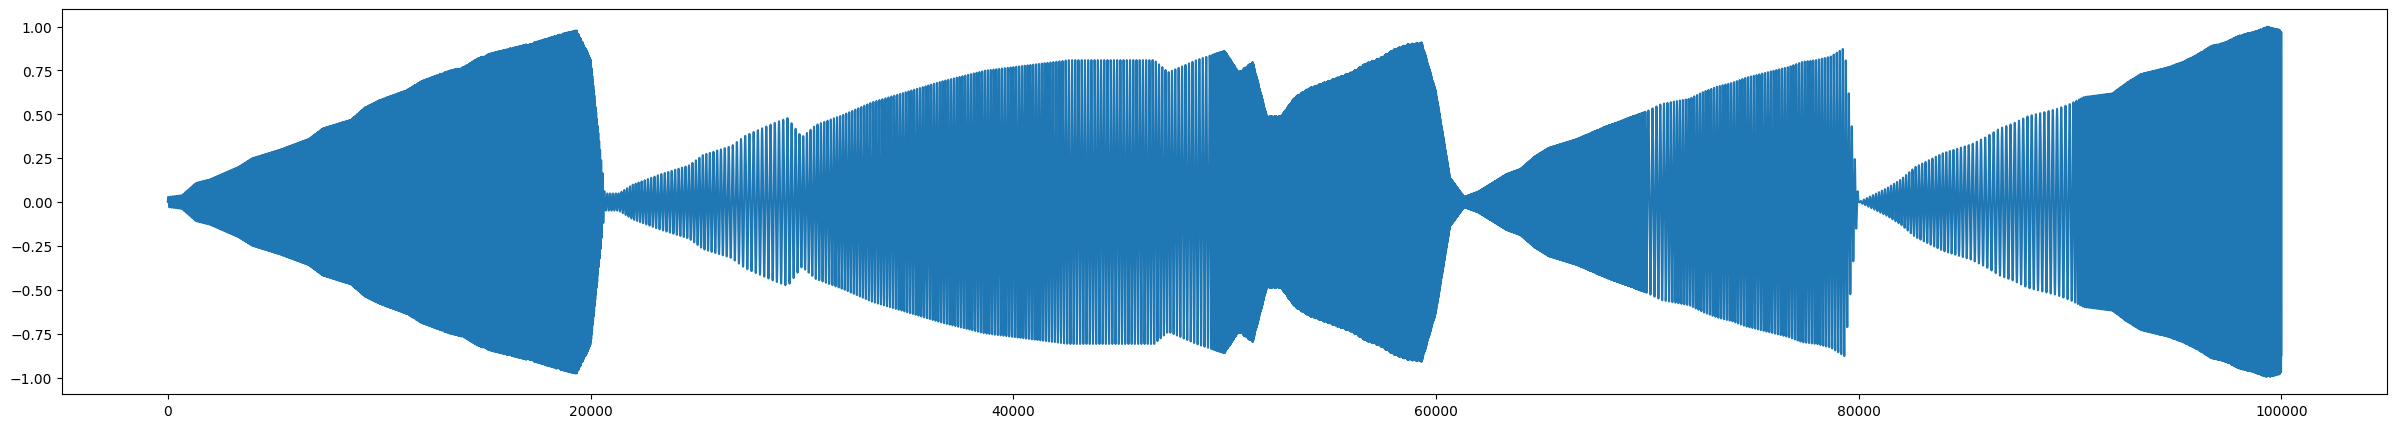

In [ ]:


plt.figure(figsize=(30, 5)) 
plt.plot(vib_signal)
plt.show()


In [14]:
df

,Time(ms),Kp,Ki,Kd,CurrentTemp,TargetTemp,PWM,DeltaTemp,Step,BreakTime
0,286532,128.0,8.0,16.0,32.82,32.91,-114.02,0.41,0,0
1,286545,128.0,8.0,16.0,32.82,32.91,-130.73,0.41,0,0
2,286532,128.0,8.0,16.0,32.82,32.91,-114.02,0.41,0,0
3,286545,128.0,8.0,16.0,32.82,32.91,-130.73,0.41,0,0
4,286532,128.0,8.0,16.0,32.82,32.91,-114.02,0.41,0,0
...,...,...,...,...,...,...,...,...,...,...
3659,46136,128.0,8.0,16.0,32.72,32.69,-106.65,0.19,0,0
3660,46148,128.0,8.0,16.0,32.72,32.69,-106.65,0.19,0,0
3661,46161,128.0,8.0,16.0,32.72,32.69,-106.65,0.19,0,0
3662,46174,128.0,8.0,16.0,32.82,32.69,-106.65,0.19,0,0


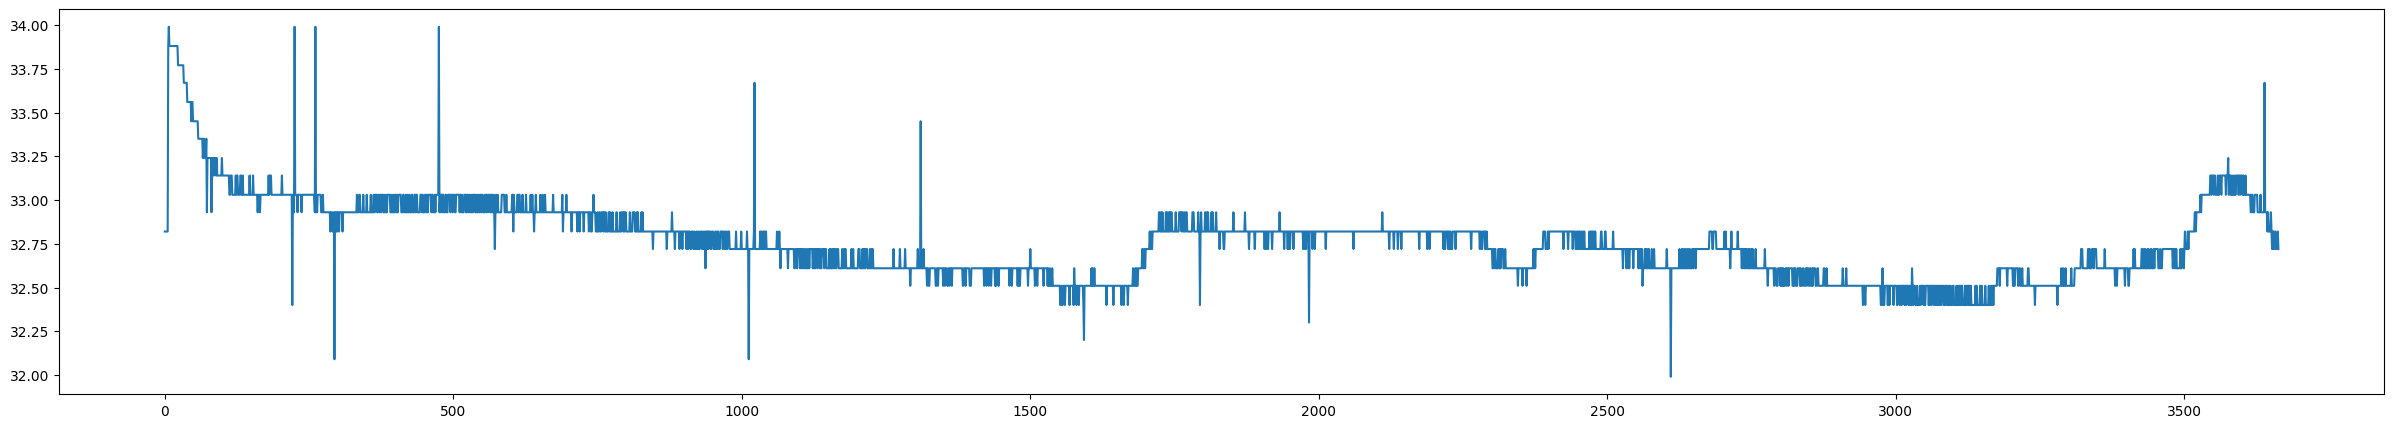

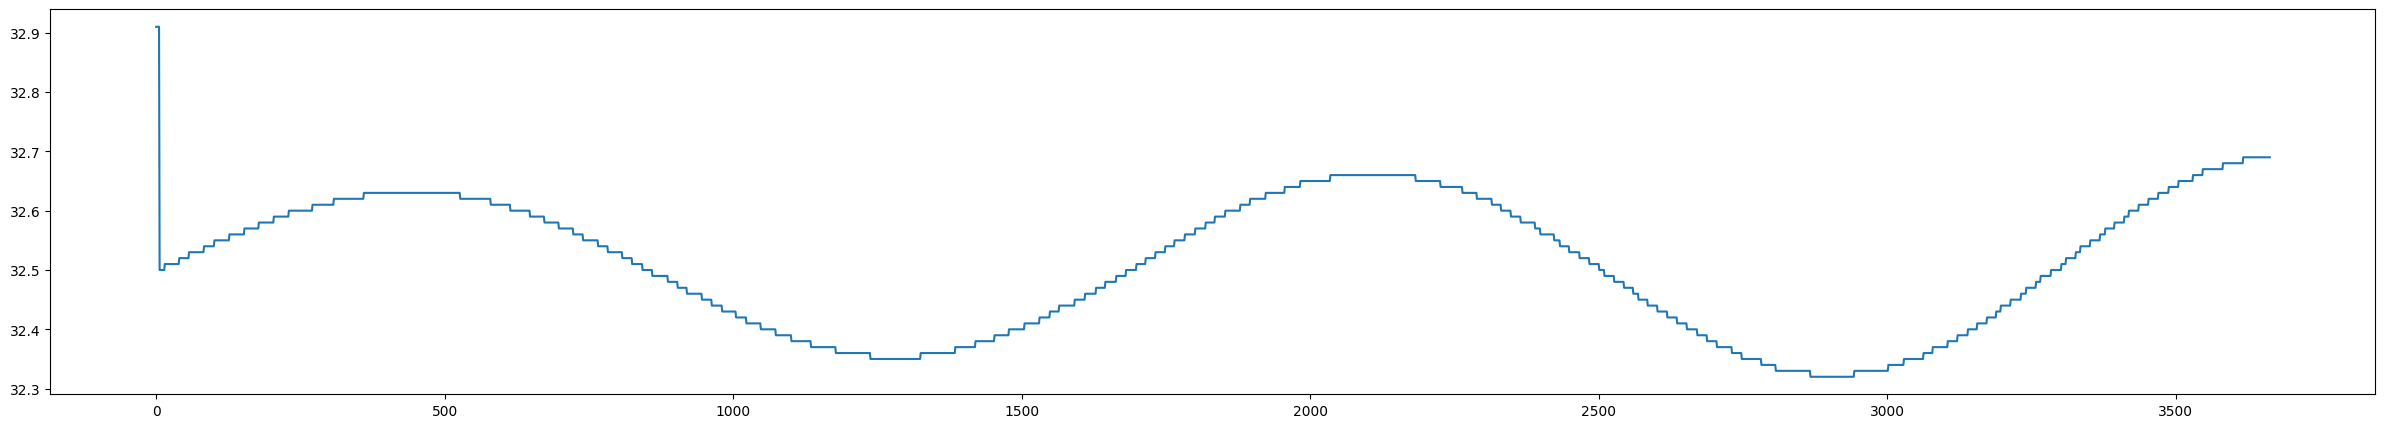

In [ ]:

df = pd.read_csv('arduino_log.csv')

plt.figure(figsize=(30, 5)) 
plt.plot(df['CurrentTemp'])
plt.show()


plt.figure(figsize=(30, 5)) 
plt.plot(df['TargetTemp'])
plt.show()

plt.figure(figsize=(30, 5))  
plt.plot(thr_amp)
plt.show()

In [6]:
## DAQ 구동 파트
import nidaqmx

def Init_DAQ():
    ## DAQ Ready
    system = nidaqmx.system.System.local()
    for device in system.devices:
        print(device)
    device = system.devices['Dev1']
    out_chan = device.ao_physical_chans['ao0']
    
    return out_chan.name

def Run_DAQ(out_chan, vib_signal):
    ## DAQ Run
    with nidaqmx.Task() as task:
        task.ao_channels.add_ao_voltage_chan(out_chan)
        task.timing.cfg_samp_clk_timing(SAMPLE_RATE, sample_mode=nidaqmx.constants.AcquisitionType.FINITE, samps_per_chan=SAMPLE_RATE * TOTAL_DURATION_SEC)
        
        task.write(vib_signal, auto_start=True)
        task.wait_until_done()
        task.stop()

In [7]:
out_chan = Init_DAQ()
Run_DAQ(out_chan, vib_signal_result)

Device(name=Dev1)


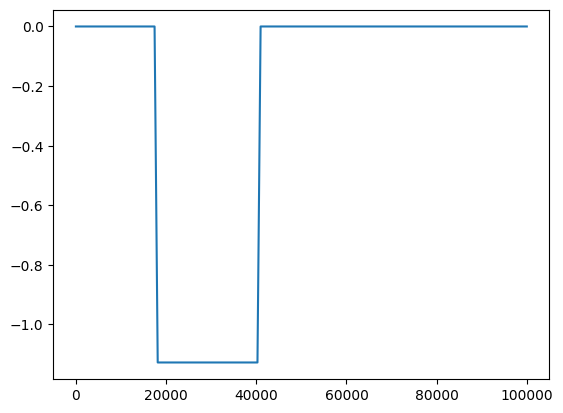

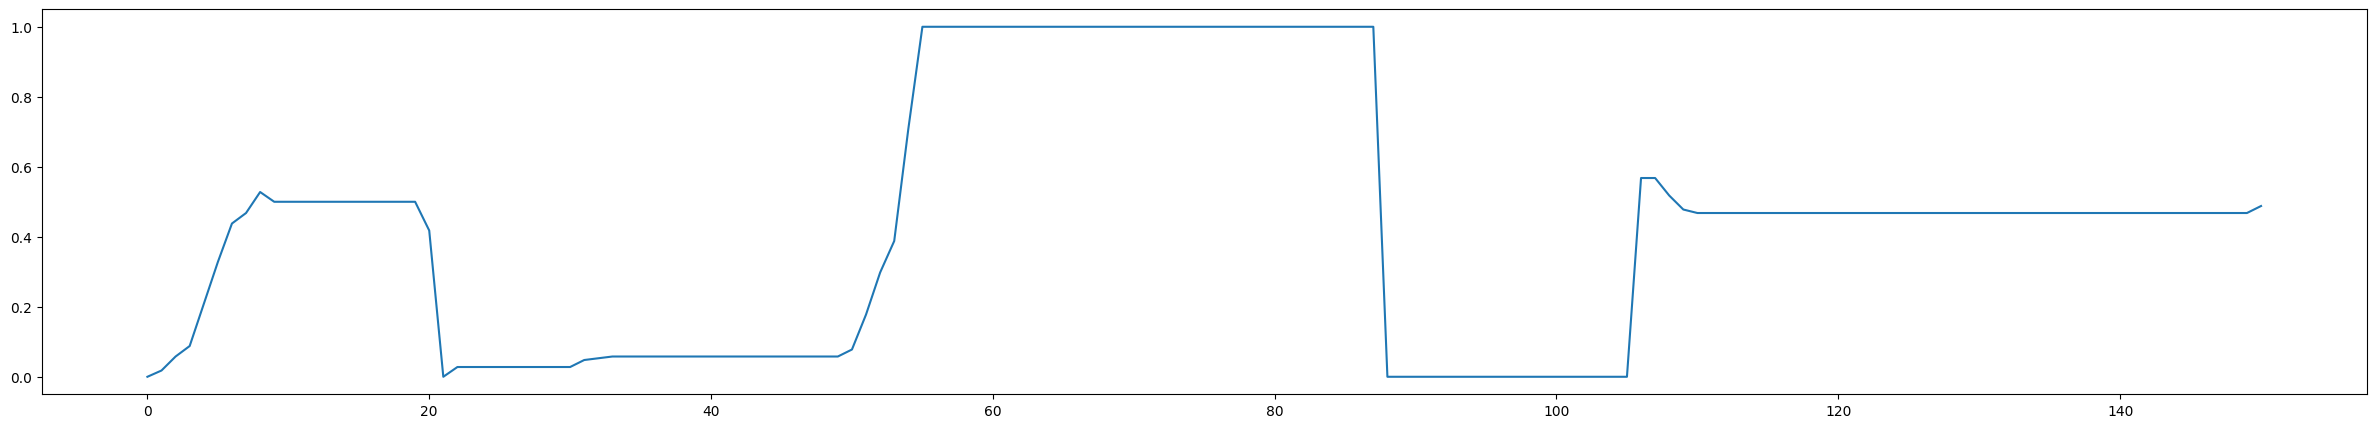

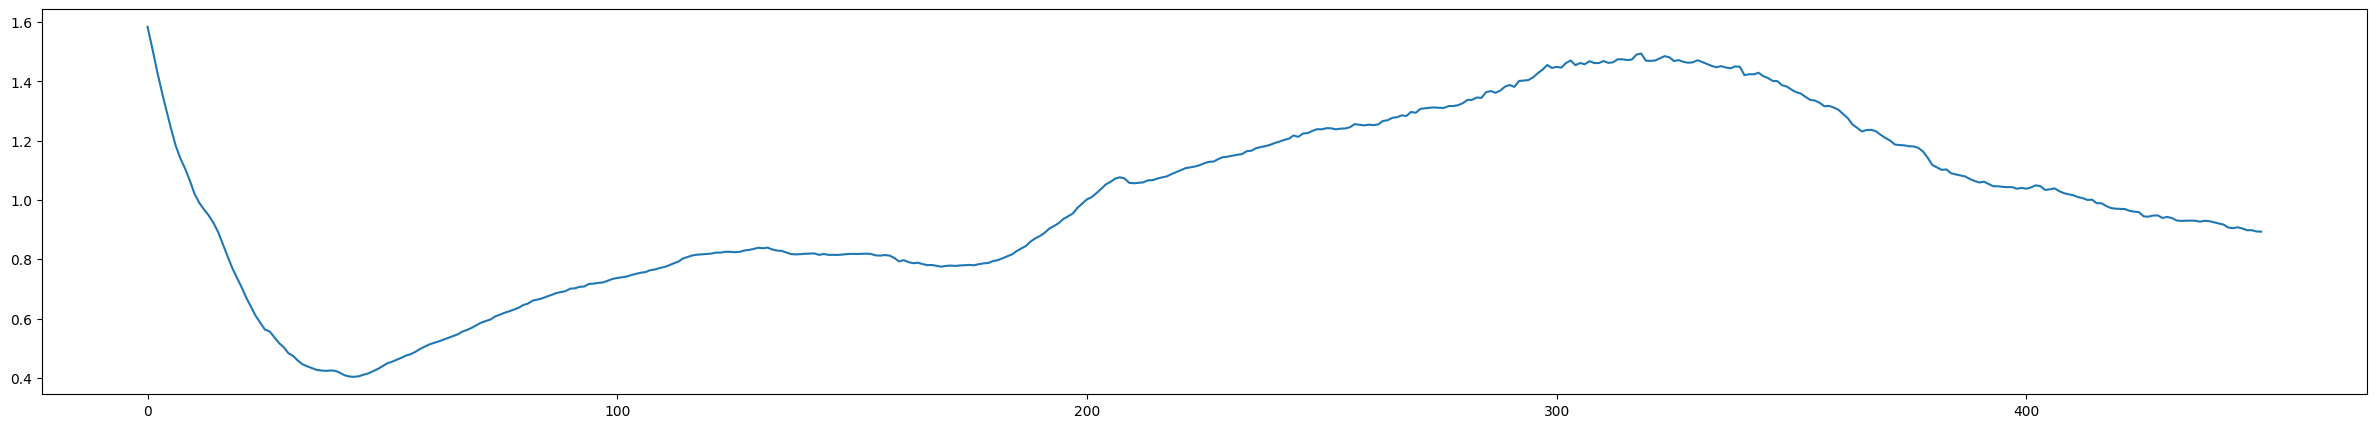

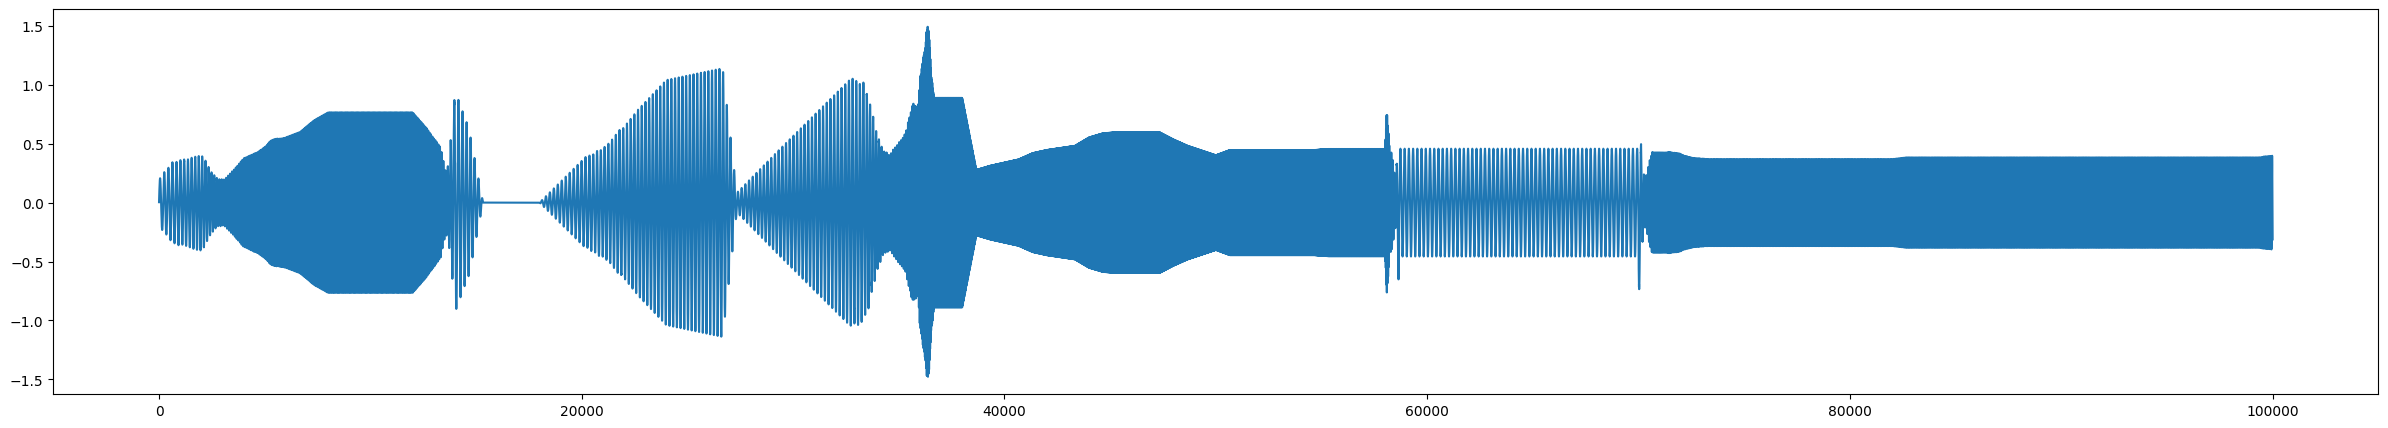

In [8]:
freq = data['vib_freq']
plt.plot(thr_amp)
plt.show()
plt.figure(figsize=(30, 5))  
plt.plot(freq)
plt.figure(figsize=(30, 5))  
plt.plot(Coeffs)
plt.figure(figsize=(30, 5))  
plt.plot(vib_signal_result)
plt.show()

## Arduino - Thermal device

In [9]:
import serial
import time
import json
import numpy as np
import csv
import threading
import nidaqmx
from nidaqmx.constants import AcquisitionType


# DAQ 초기화 및 실행 함수

def Init_DAQ():
    system = nidaqmx.system.System.local()
    for device in system.devices:
        print("[DAQ] Device Found:", device)
    device = system.devices['Dev1']
    out_chan = device.ao_physical_chans['ao0']
    return out_chan.name

def Run_DAQ(out_chan, vib_signal):
    with nidaqmx.Task() as task:
        task.ao_channels.add_ao_voltage_chan(out_chan)
        task.timing.cfg_samp_clk_timing(SAMPLE_RATE,
                                        sample_mode=AcquisitionType.FINITE,
                                        samps_per_chan=SAMPLE_RATE * TOTAL_DURATION_SEC)
        print("[DAQ] Writing signal to channel...")
        task.write(vib_signal, auto_start=True)
        task.wait_until_done()
        task.stop()
        print("[DAQ] Finished")

# 아두이노 시리얼 연결
ser = serial.Serial('COM3', 115200)
time.sleep(2)

# JSON에서 데이터 불러오기
with open('collected_data.json') as f:
    data = json.load(f)


# vib_signal_result,  duration = generate_signal(vib_amp, vib_freq, duration=10.0)

# CSV 로그 파일 설정
csv_file = open('arduino_log.csv', 'w', newline='')
csv_writer = csv.writer(csv_file)
csv_writer.writerow(['Time(ms)', 'Kp', 'Ki', 'Kd', 'CurrentTemp', 'TargetTemp', 'PWM', 'DeltaTemp', 'Step', 'BreakTime'])

# DAQ 시작
out_chan = Init_DAQ()
daq_thread = threading.Thread(target=Run_DAQ, args=(out_chan, vib_signal_result))
daq_thread.start()

print("[System] DAQ started. Beginning Arduino streaming...")

start_time = time.time()

for idx, delta_temp in enumerate(vib_signal):
    command = f"{delta_temp:.3f}\n"
    ser.write(command.encode())
    print(f"[Sample {idx+1}/{len(vib_signal)}] Sent:", command.strip())

    t0 = time.time()
    while time.time() - t0 < 0.1:
        while ser.in_waiting:
            try:
                line = ser.readline().decode('utf-8', errors='replace').strip()
                print("Arduino:", line)
                if line.endswith(';') and ',' in line:
                    fields = line.replace(';', '').split(',')
                    if len(fields) == 10:
                        csv_writer.writerow(fields)
            except Exception as e:
                print("Decode error:", e)
        time.sleep(0.01)

# DAQ 종료 대기 및 정리
daq_thread.join()
ser.close()
csv_file.close()
print("✅ All signals sent, DAQ complete, and logs saved.")

[DAQ] Device Found: Device(name=Dev1)
[System] DAQ started. Beginning Arduino streaming...
[Sample 1/100000] Sent: 0.004
Arduino: 600,8.00,16.00,32.82,32.91,-130.73,0.41,0,0;
Arduino: 4.02,0.41,0,0;
[DAQ] Writing signal to channel...
Arduino: 286532,128.00,8.00,16.00,32.82,32.91,-114.02,0.41,0,0;
Arduino: 286545,128.00,8.00,16.00,32.82,32.91,-130.73,0.41,0,0;
Arduino: 4.02,0.41,0,0;
Arduino: 286532,128.00,8.00,16.00,32.82,32.91,-114.02,0.41,0,0;
Arduino: 286545,128.00,8.00,16.00,32.82,32.91,-130.73,0.41,0,0;
Arduino: 4.02,0.41,0,0;
Arduino: 286532,128.00,8.00,16.00,32.82,32.91,-114.02,0.41,0,0;
Arduino: 286545,128.00,8.00,16.00,32.82,32.91,-130.73,0.41,0,0;
Arduino: READY
Arduino: Target Temperature: 32.50 degC
Arduino: 447,128.00,8.00,16.00,33.88,32.50,-255.00,0.00,0,0;
Arduino: 459,128.00,8.00,16.00,33.99,32.50,-255.00,0.00,0,0;
Arduino: 472,128.00,8.00,16.00,33.88,32.50,-255.00,0.00,0,0;
Arduino: 484,128.00,8.00,16.00,33.88,32.50,-255.00,0.00,0,0;
Arduino: 496,128.00,8.00,16.00,33.8

KeyboardInterrupt: 